In [39]:
!git add .
!git commit -m "insurance"
!git push -u origin main

[main 8c846e4] insurance
 1 file changed, 71 insertions(+), 9 deletions(-)
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 10 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 1.11 KiB | 1.11 MiB/s, done.
Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/pankajvshnv/Data-Science.git
   97866fc..8c846e4  main -> main
branch 'main' set up to track 'origin/main'.


In [30]:
import pandas as pd


In [10]:
data = pd.read_csv("insurance.csv")
df = data

In [21]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [27]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### EDA

In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [53]:
numerical_data = [ "age", "bmi", "children", "charges"]

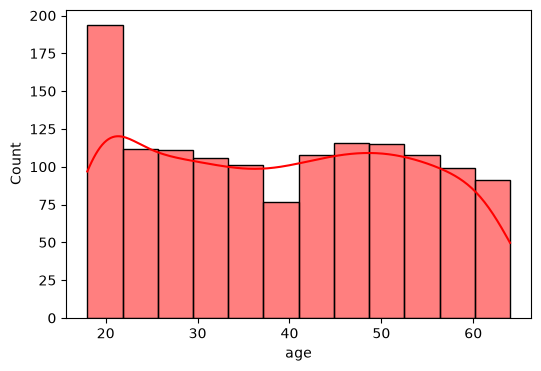

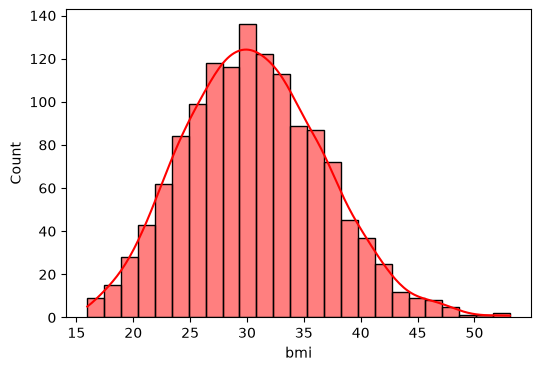

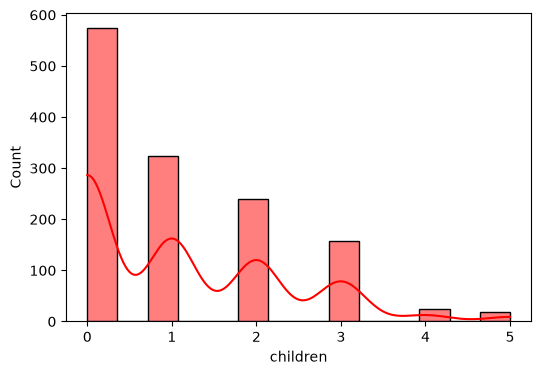

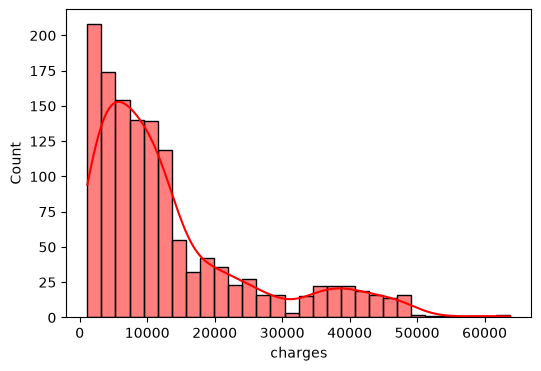

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
for i in numerical_data:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x=i, kde=True, color='r')
    plt.show()




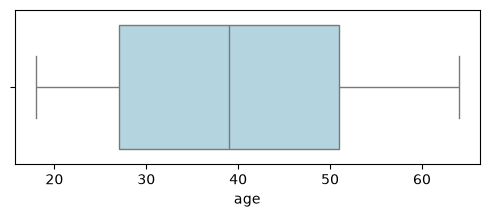

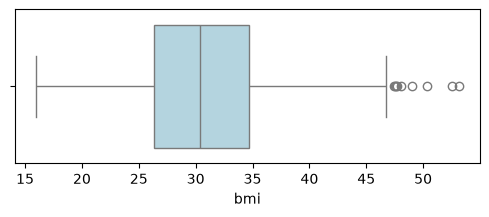

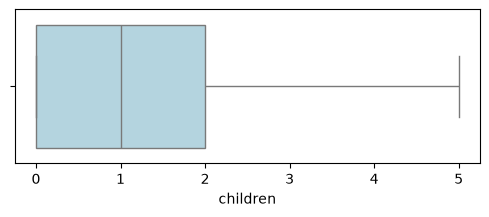

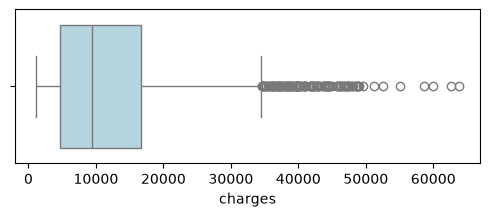

In [66]:
for i in numerical_data:
    plt.figure(figsize=(6, 2))
    sns.boxplot(data=df, x=i, color='lightblue')
    plt.show()

In [67]:
import numpy as np

for i in numerical_data:
    mean = df[i].mean()
    std_dev = df[i].std()
    
    
    df['z_score'] = (df[i] - mean) / std_dev
    
 
    outliers_z = df[np.abs(df['z_score']) > 3]
    
    print(f"Outliers for {i}:")
    print(outliers_z[[i, 'z_score']])
    print("-" * 30)

Outliers for age:
Empty DataFrame
Columns: [age, z_score]
Index: []
------------------------------
Outliers for bmi:
        bmi   z_score
116   49.06  3.016733
847   50.38  3.233191
1047  52.58  3.593954
1317  53.13  3.684145
------------------------------
Outliers for children:
      children   z_score
32           5  3.239407
71           5  3.239407
166          5  3.239407
413          5  3.239407
425          5  3.239407
438          5  3.239407
568          5  3.239407
640          5  3.239407
877          5  3.239407
932          5  3.239407
937          5  3.239407
969          5  3.239407
984          5  3.239407
1085         5  3.239407
1116         5  3.239407
1130         5  3.239407
1245         5  3.239407
1272         5  3.239407
------------------------------
Outliers for charges:
          charges   z_score
34    51194.55914  3.131635
543   63770.42801  4.170104
577   58571.07448  3.740761
819   55135.40209  3.457055
1146  52590.82939  3.246934
1230  60021.39897  3.86

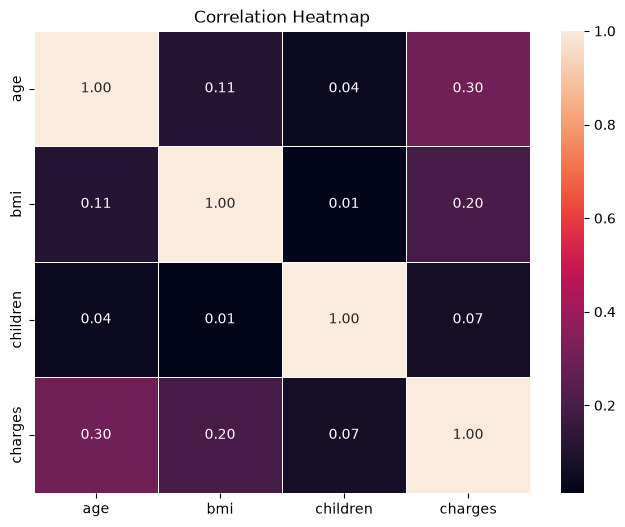

In [79]:
plt.figure(figsize=(8, 6))

corr_matrix = df[numerical_data].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap')
plt.show()

## data cleaning and preprocessing

In [75]:
df.drop_duplicates(inplace = True)

/var/folders/4t/xyd6v_lj5m38ffp9mpcjv05r0000gn/T/ipykernel_39410/3424306917.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace = True)


In [76]:
df

,age,sex,bmi,children,smoker,region,charges,z_score
0,19,female,27.900,0,yes,southwest,16884.92400,0.298472
1,18,male,33.770,1,no,southeast,1725.55230,-0.953333
2,28,male,33.000,3,no,southeast,4449.46200,-0.728402
3,33,male,22.705,0,no,northwest,21984.47061,0.719574
4,32,male,28.880,0,no,northwest,3866.85520,-0.776512
...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,-0.220468
1334,18,female,31.920,0,no,northeast,2205.98080,-0.913661
1335,18,female,36.850,0,no,southeast,1629.83350,-0.961237
1336,21,female,25.800,0,no,southwest,2007.94500,-0.930014


In [88]:
df['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

## labeled Encoding

In [93]:
df['sex'] = df['sex'].map({
    "male" : 0,
    "female": 1
        })

In [94]:
df

,age,sex,bmi,children,smoker,region,charges,z_score
0,19,1,27.900,0,yes,southwest,16884.92400,0.298472
1,18,0,33.770,1,no,southeast,1725.55230,-0.953333
2,28,0,33.000,3,no,southeast,4449.46200,-0.728402
3,33,0,22.705,0,no,northwest,21984.47061,0.719574
4,32,0,28.880,0,no,northwest,3866.85520,-0.776512
...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,no,northwest,10600.54830,-0.220468
1334,18,1,31.920,0,no,northeast,2205.98080,-0.913661
1335,18,1,36.850,0,no,southeast,1629.83350,-0.961237
1336,21,1,25.800,0,no,southwest,2007.94500,-0.930014


In [99]:
df['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [102]:
df['smoker'] = df['smoker'].map({
    "yes": 1,
    "no":0
        })

In [104]:
df.head()

,age,sex,bmi,children,smoker,region,charges,z_score
0,19,1,27.900,0,1,southwest,16884.92400,0.298472
1,18,0,33.770,1,0,southeast,1725.55230,-0.953333
2,28,0,33.000,3,0,southeast,4449.46200,-0.728402
3,33,0,22.705,0,0,northwest,21984.47061,0.719574
4,32,0,28.880,0,0,northwest,3866.85520,-0.776512


## One Hot Encoding

In [ ]:
df['region'] = df['region'].astype('category').cat.codes
df.head()